In [13]:
from HBC import HBC, add_adjusted_stats
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-paper')

In [ ]:
comparisons = [
    ('control_open', 'truth'),
    ('control_periodic', 'truth'),
    ('open', 'truth'),
    ('periodic', 'truth'),
    ('control_open', 'control_periodic'),
    ('periodic', 'open')
]

def fcn_rel_rmse(r1, r2):
    """RMSE of r2 relative to r1"""
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return 100 * (np.sum((r2 - r1)**2)**0.5) / (np.sum(r1**2)**0.5)

def fcn_rel_bias(r1, r2):
    """Bias of r2 relative to r1"""
    return 100 * (np.nansum(np.abs(r2)) - np.nansum(np.abs(r1))) / (np.nansum(np.abs(r1)))

def fcn_MBE(r1, r2):
    """Mean bias error"""
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return (1/len(r1)) * np.sum(r2 - r1)

def fcn_RMSD(r1, r2):
    """Root Mean Squared Difference"""
    r1[np.isnan(r1)] = 0
    r2[np.isnan(r2)] = 0
    return ((1/len(r1)) * np.sum((r2 - r1)**2))**0.5

stat_list = {
    'relative RMSE': {
        'fcn': fcn_rel_rmse
    },
    'relative bias': {
        'fcn': fcn_rel_bias
    },
    'MBE': {
        'fcn': fcn_MBE
    },
    'RMSD': {
        'fcn': fcn_RMSD
    }
}

In [15]:
lens = [5, 7, 9, 11, 15, 19]
# cloud_field = 'TradeCumulus'
cloud_field = 'Transition'
periodic_bases = [f'/data/keeling/a/johntl3/b/Synthetic/IO/thesis_periodic_V2/{cloud_field}/len{l:03d}/ex00' for l in lens]
open_bases = [f'/data/keeling/a/johntl3/b/Synthetic/IO/thesis/{cloud_field}/len{l:03d}/ex00' for l in lens]
df = []
for pb, ob in zip(periodic_bases, open_bases):
    h = HBC(pb, ob)
    df.append(h.calc_stats(comparisons, stat_list))
df = pd.concat(df)

df, report = add_adjusted_stats(df)

if report:
    print(f"{len(report)} issue(s) found:")
    for msg in report:
        print(" -", msg)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '2'. Max cell optical depth: '2.1615653038024902'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.

In [16]:
def plot_r1_and_r2(df, r1_name, r2_name, x_axis='T', stat_list=None, ax=None):
    sub = df[(df['r1_name'] == r1_name) & (df['r2_name'] == r2_name)]
    if stat_list is None:
        stat_list = sub['stat_name'].unique()
    if ax is None:
        f, ax = plt.subplots(1, len(stat_list), figsize=(5*len(stat_list),5))
    for i, s in enumerate(stat_list):
        sub[(sub['stat_name'] == s)].pivot(columns='R',values='stat',index=x_axis).plot(marker='o', ax=ax[i])
        ax[i].grid()
        ax[i].set_ylabel(s)
        ax[i].set_title(s)
    plt.suptitle(f'R1 = {r1_name}, R2 = {r2_name}')

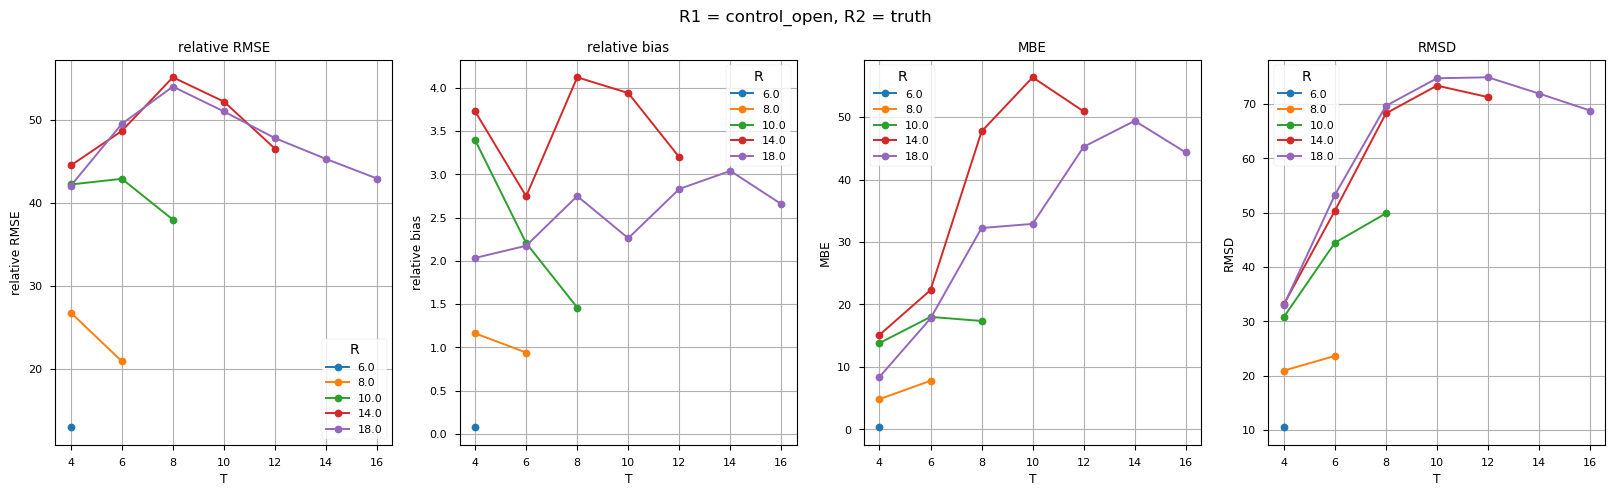

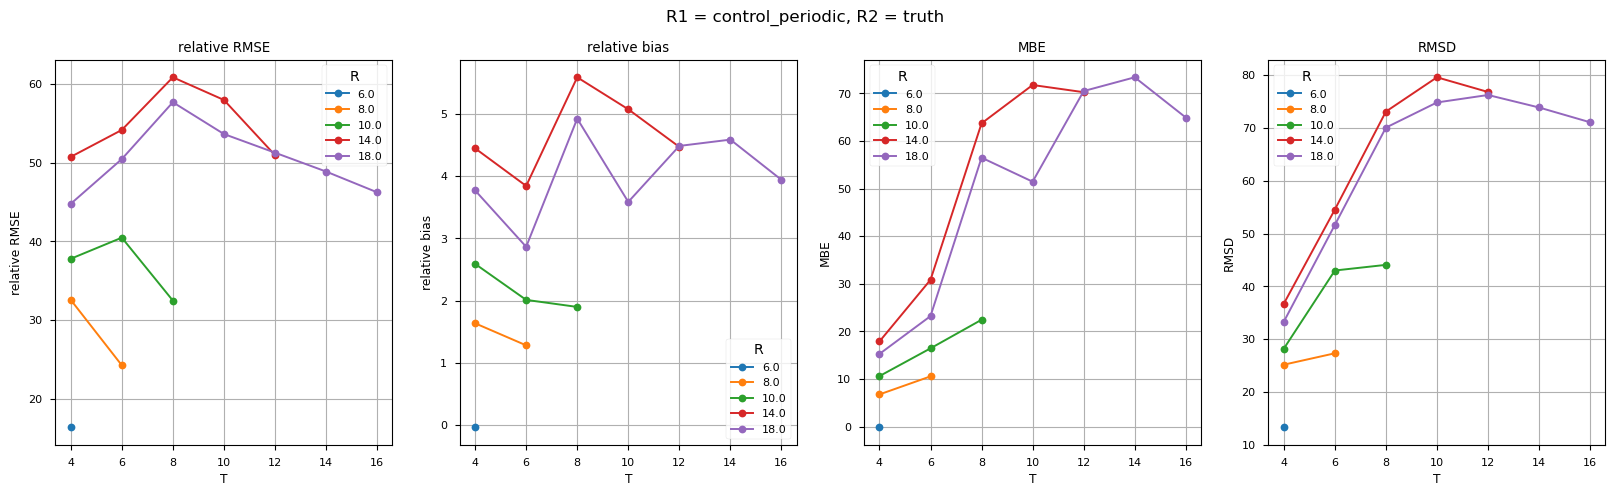

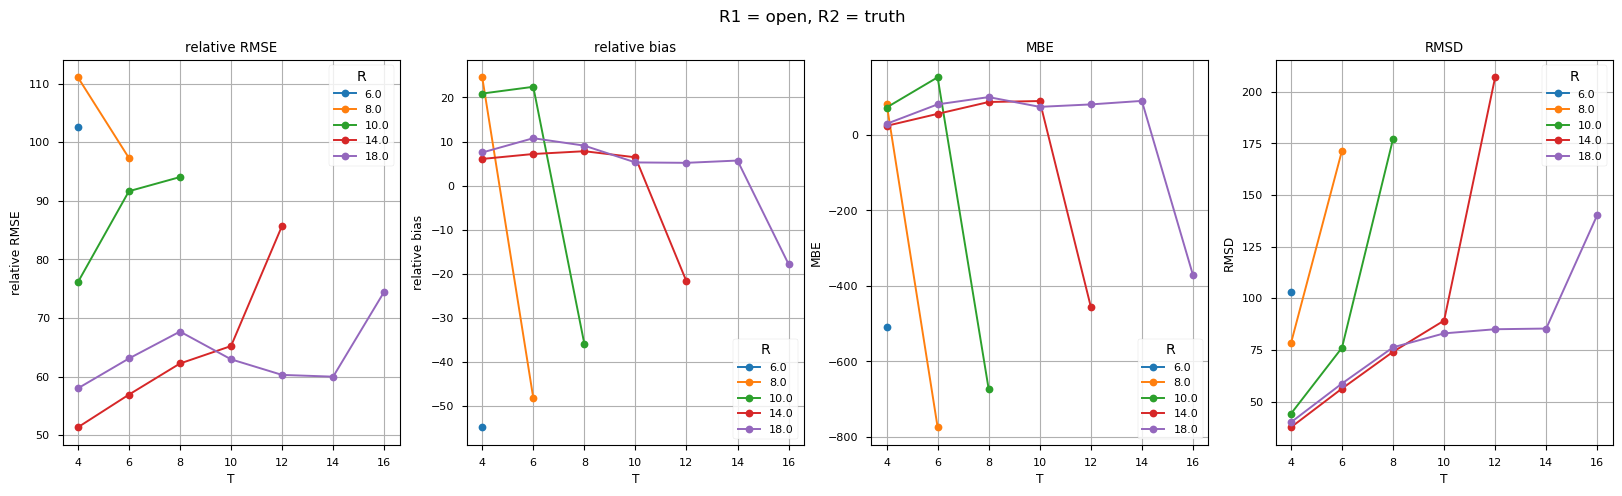

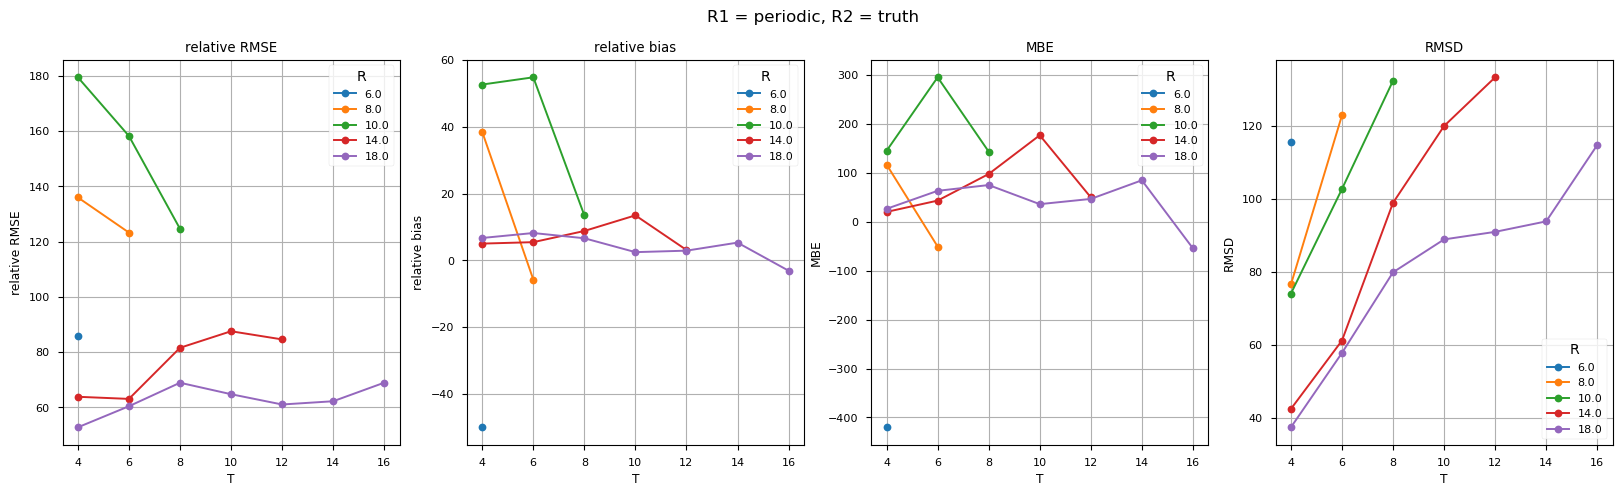

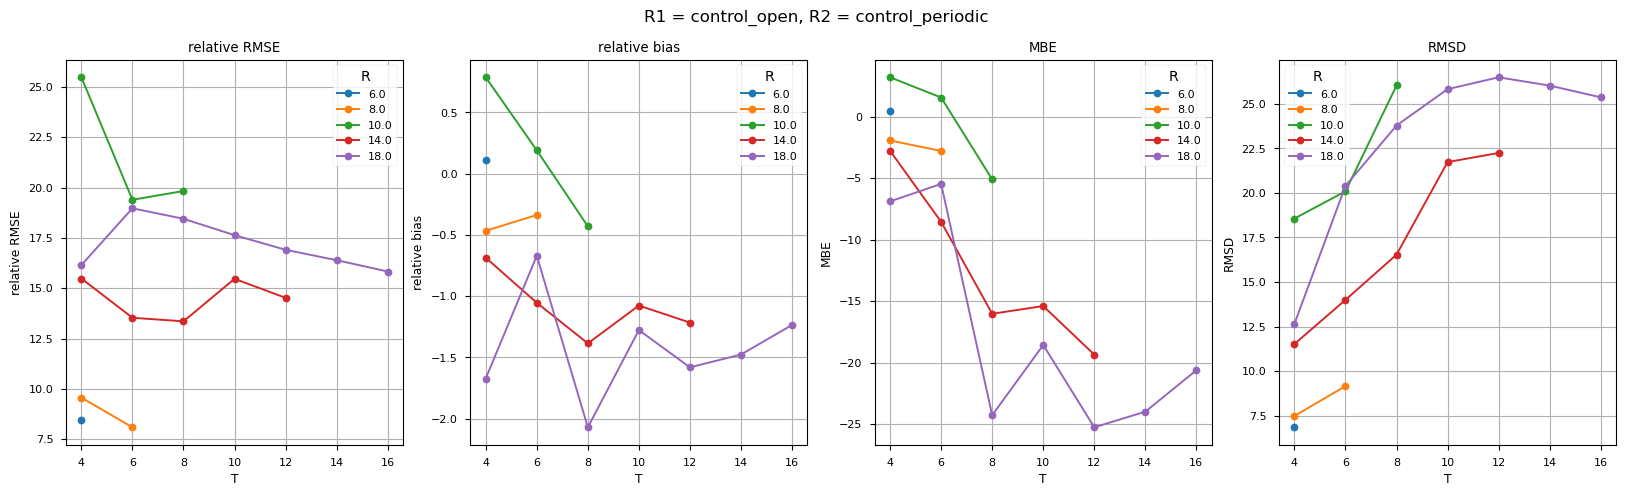

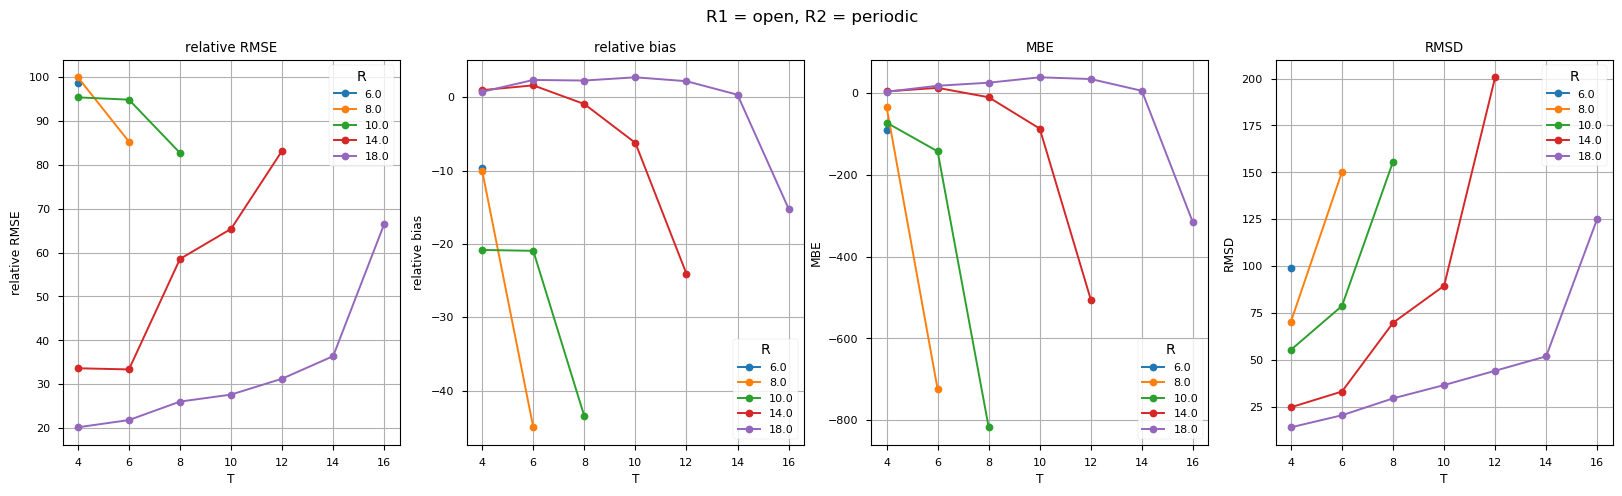

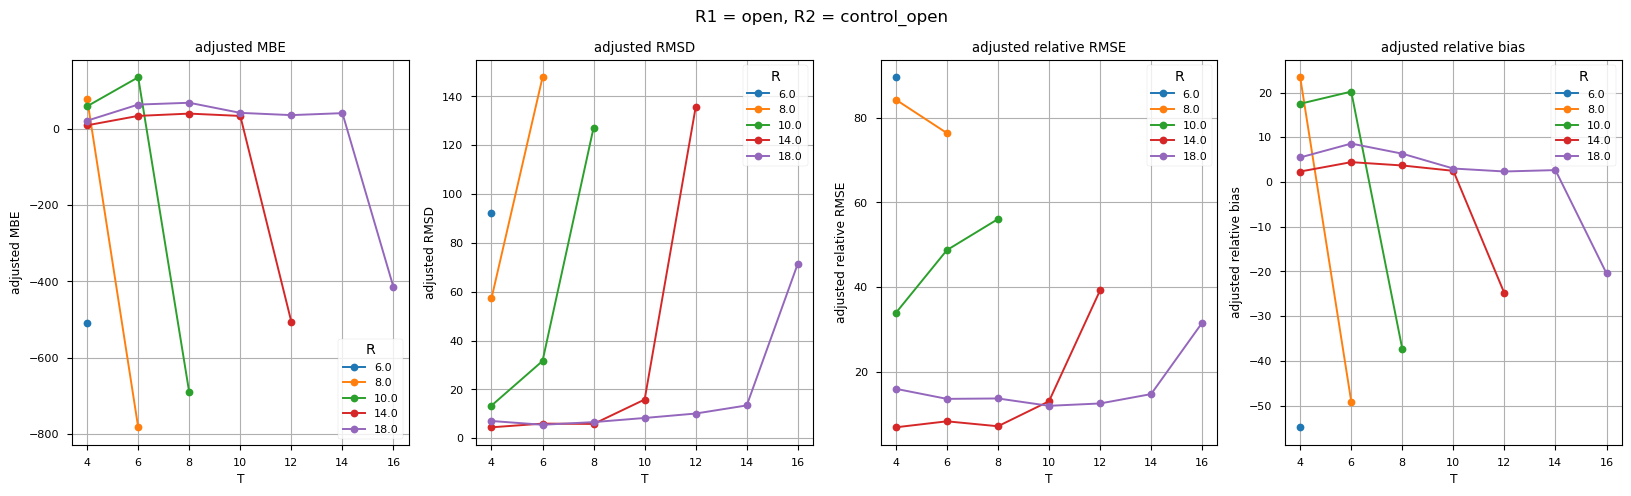

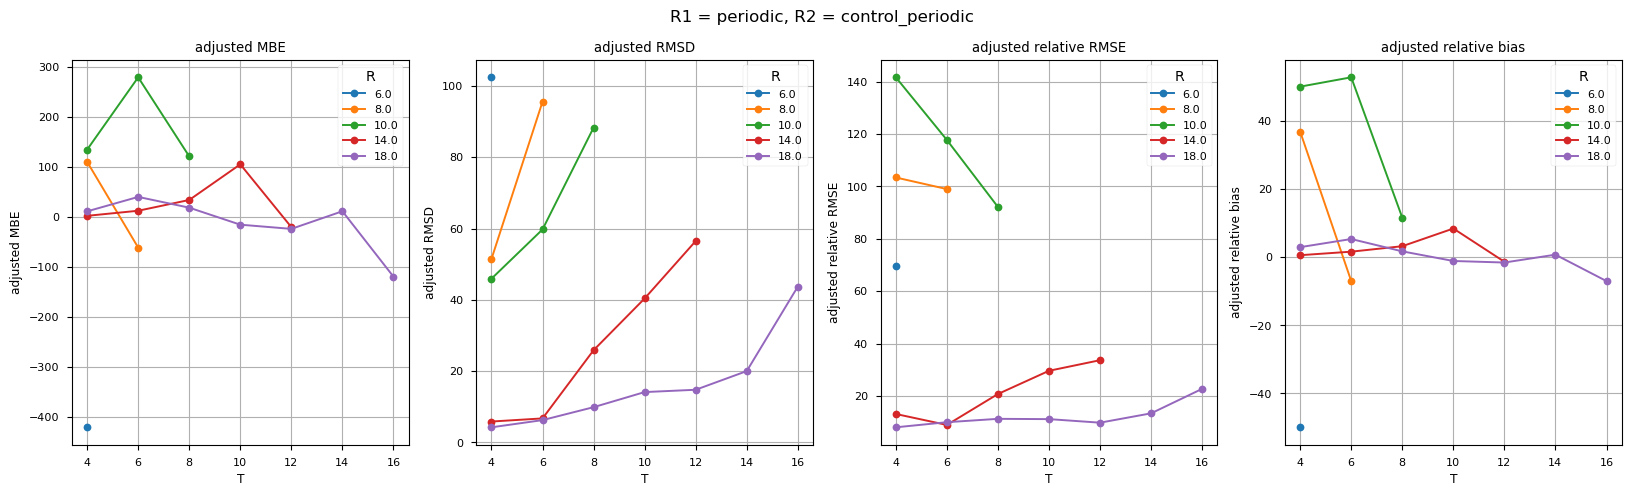

In [17]:
r1r2pairs = comparisons.copy()
r1r2pairs.append(('open', 'control_open'))
r1r2pairs.append(('periodic', 'control_periodic'))

for r1_tmp, r2_tmp in r1r2pairs:
    plot_r1_and_r2(df[(df['T'] >= 4) & (df['R'] >= 6)], r1_tmp, r2_tmp, x_axis='T')

In [18]:
def _base_and_role(r1_name):
    """Return (base_name, role) where role is 'experiment' or 'control'."""
    if r1_name.startswith('control_'):
        return r1_name[len('control_'):], 'control'
    return r1_name, 'experiment'


def plot_vs_R_minus_T(df, stat_name, ax=None):
    """
    Scatter plot of `stat` vs `R-T` for a single stat_name.

    Includes:
      - experiment rows: (open, truth), (periodic, truth)
      - control rows:    (control_open, truth), (control_periodic, truth)
      - adjusted rows:   (open, control_open), (periodic, control_periodic)
        [only present when stat_name starts with 'adjusted ']

    Series are distinguished by:
      - color: open vs periodic (base name)
      - marker/linestyle proxy: experiment vs control (only relevant for
        non-adjusted stat_names, since adjusted stats only have one role)
    """
    sub = df[df['stat_name'] == stat_name].copy()

    is_adjusted = stat_name.startswith('adjusted ')

    if is_adjusted:
        # rows are (open, control_open) or (periodic, control_periodic)
        sub = sub[sub['r2_name'].str.startswith('control_')]
        sub['base'] = sub['r1_name']  # r1_name is already 'open' / 'periodic'
        sub['role'] = 'adjusted'
    else:
        # rows are (X, truth) where X is open/periodic/control_open/control_periodic
        sub = sub[sub['r2_name'] == 'truth']
        sub[['base', 'role']] = sub['r1_name'].apply(
            lambda x: pd.Series(_base_and_role(x))
        )

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    markers = {'experiment': 'o', 'control': 'x', 'adjusted': 'o'}
    palette = {'open': 'tab:blue', 'periodic': 'tab:orange'}

    for (base, role), group in sub.groupby(['base', 'role']):
        ax.scatter(
            group['R-T'], group['stat'],
            color=palette.get(base, 'gray'),
            marker=markers.get(role, 'o'),
            label=f"{base} ({role})",
            alpha=0.7,
        )

    ax.set_xlabel('R-T')
    ax.set_ylabel(stat_name)
    ax.set_title(stat_name)
    ax.legend()
    return ax

In [19]:
def plot_vs_T_by_R(df, stat_name, ax=None):
    """
    Same as plot_vs_R_minus_T, but x-axis is T. Points are connected by
    lines within each (base, role, R, source path) group -- i.e. one line
    per distinct experiment (source path) at a given R, colored by R and
    styled by open/periodic + experiment/control/adjusted role.
    """
    sub = df[df['stat_name'] == stat_name].copy()

    is_adjusted = stat_name.startswith('adjusted ')

    if is_adjusted:
        sub = sub[sub['r2_name'].str.startswith('control_')]
        sub['base'] = sub['r1_name']
        sub['role'] = 'adjusted'
    else:
        sub = sub[sub['r2_name'] == 'truth']
        sub[['base', 'role']] = sub['r1_name'].apply(
            lambda x: pd.Series(_base_and_role(x))
        )

    # identify a single experiment by its pair of source paths
    sub['source_key'] = sub['open_source'] + ' | ' + sub['periodic_source']

    if ax is None:
        fig, ax = plt.subplots(figsize=(9, 5))

    markers = {'open': 'o', 'periodic': 's'}
    linestyles = {'experiment': '-', 'control': '--', 'adjusted': '-'}

    R_values = sorted(sub['R'].unique())
    cmap = plt.get_cmap('viridis')
    colors = {R: cmap(i / max(len(R_values) - 1, 1)) for i, R in enumerate(R_values)}

    seen_labels = set()
    for (base, role, R_val, source_key), group in sub.groupby(
        ['base', 'role', 'R', 'source_key']
    ):
        group = group.sort_values('T')
        label = f"{base} ({role}), R={R_val}"
        # avoid duplicate legend entries across different source paths
        show_label = label not in seen_labels
        seen_labels.add(label)

        ax.plot(
            group['T'], group['stat'],
            color=colors[R_val],
            marker=markers.get(base, 'o'),
            linestyle=linestyles.get(role, '-'),
            alpha=0.7,
            label=label if show_label else None,
        )

    ax.set_xlabel('T')
    ax.set_ylabel(stat_name)
    ax.set_title(stat_name)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    return ax

In [20]:
# for stat_name in df['stat_name'].unique():
#     fig, ax = plt.subplots(figsize=(8, 5))
#     plot_vs_R_minus_T(df[df['T'] >= 4], stat_name, ax=ax)
#     plt.tight_layout()
#     plt.show()

In [21]:
# for stat_name in df['stat_name'].unique():
#     fig, ax = plt.subplots(figsize=(9, 5))
#     plot_vs_T_by_R(df[df['T'] >= 4], stat_name, ax=ax)
#     plt.tight_layout()
#     plt.show()

In [25]:
# plot_kwargs = {
#     'y':'z',
#     'vmin': 0,
#     'vmax': 27,
#     'cmap': 'gist_heat_r'
# }
# diff_kwargs = {
#     'y':'z',
#     'vmin': -5,
#     'vmax': 5,
#     'cmap': 'RdBu_r'
# }

# xi = 1
# for xi in range(h.ext.dims['x']):
#     tmp = h.ext.isel(x=xi).copy(deep=True)
#     f, ax = plt.subplots(2, 3, figsize=(15,6), sharex=True, sharey=True)
#     tmp.open.plot(ax=ax[0,0], **plot_kwargs)
#     tmp.truth.plot(ax=ax[0,1], **plot_kwargs)
#     tmp.periodic.plot(ax=ax[0,2], **plot_kwargs)
#     ax[0,0].set_title('open')
#     ax[0,1].set_title('truth')
#     ax[0,2].set_title('periodic')

#     (tmp.open - tmp.truth).plot(ax=ax[1,0], **diff_kwargs)
#     (tmp.periodic - tmp.open).plot(ax=ax[1,1], **diff_kwargs)
#     (tmp.periodic - tmp.truth).plot(ax=ax[1,2], **diff_kwargs)
#     ax[1,0].set_title('open - truth')
#     ax[1,1].set_title('periodic - open')
#     ax[1,2].set_title('periodic - truth')
#     f.suptitle(f'x = {tmp.x.data}')